# Lab 02 · 학습이 잘 되게 만드는 부품들: Adam, 학습률, 잔차 연결, 드롭아웃

**이 실습이 다루는 자료** ([필독 목록](../READING_LIST.md) · [실습 가이드](../PRACTICE.md))

| 절 | 직접 확인할 것 | 관련 자료 |
|---|---|---|
| 1 | Adam을 논문의 Algorithm 1 그대로 구현하고 PyTorch와 대조 | Kingma & Ba (2014) *Adam* |
| 2 | 옵티마이저별로 "잘 되는 학습률 범위"가 얼마나 다른가 | Adam, *Deep Learning Tuning Playbook* |
| 3 | 깊은 plain 망은 **학습 오차**부터 나빠지고, 잔차 연결이 이를 해결 | He et al. (2015) *ResNet* — [풀이 예시 노트](../2026-11-16_resnet-deep-residual-learning/summary.md) |
| 4 | 틀린 라벨까지 외우는 신경망과 드롭아웃의 효과 | Srivastava et al. (2014) *Dropout*, Zhang et al. (2016) *Rethinking Generalization* |
| 5 | `model.train()` 과 `model.eval()` 의 차이 | BatchNorm (2015), Dropout |

**소요 시간**: 90분 · **패키지**: numpy, matplotlib, scikit-learn, torch (CPU로 2분 이내 실행)

In [1]:
import numpy as np, matplotlib.pyplot as plt, torch, torch.nn as nn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
plt.rcParams.update({"figure.figsize": (7, 3.5), "figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

X, y = load_digits(return_X_y=True)               # 8x8 손글씨 숫자 1,797장 (scikit-learn 내장, 다운로드 불필요)
X_tr, X_te, y_tr, y_te = train_test_split(X / 16.0, y, test_size=0.3, random_state=0, stratify=y)
X_tr, X_te = torch.tensor(X_tr, dtype=torch.float32), torch.tensor(X_te, dtype=torch.float32)
y_tr, y_te = torch.tensor(y_tr), torch.tensor(y_te)
loss_fn = nn.CrossEntropyLoss()
print("train:", tuple(X_tr.shape), " test:", tuple(X_te.shape))

train: (1257, 64)  test: (540, 64)


## 1. Adam을 논문 그대로 구현하기 (Kingma & Ba, 2014 — Algorithm 1)

논문의 알고리즘 상자는 다섯 줄입니다. $g_t$ 는 기울기입니다.

$$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t\qquad v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2$$
$$\hat m_t=\frac{m_t}{1-\beta_1^t}\qquad \hat v_t=\frac{v_t}{1-\beta_2^t}\qquad \theta_t=\theta_{t-1}-\alpha\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}$$

- $m$: 기울기의 이동평균(방향), $v$: 기울기 제곱의 이동평균(크기)
- $\hat m,\hat v$: $m,v$ 를 0에서 시작해서 초반에 0 쪽으로 치우치는 것을 바로잡는 **bias correction**

✍️ **예측**: 기울기가 1000배 큰 문제와 1000배 작은 문제에서, Adam의 **첫 스텝 크기**는 각각 얼마일까요?

In [2]:
def adam_numpy(grad_fn, theta, steps, lr=0.1, b1=0.9, b2=0.999, eps=1e-8):
    theta = theta.copy(); m = np.zeros_like(theta); v = np.zeros_like(theta); path = [theta.copy()]
    for t in range(1, steps + 1):
        g = grad_fn(theta)
        m = b1 * m + (1 - b1) * g
        v = b2 * v + (1 - b2) * g**2
        m_hat, v_hat = m / (1 - b1**t), v / (1 - b2**t)
        theta = theta - lr * m_hat / (np.sqrt(v_hat) + eps)
        path.append(theta.copy())
    return np.array(path)

A = np.array([100.0, 1.0])                               # f(θ) = 0.5 * (100 θ0² + θ1²): 방향마다 곡률이 100배 다른 골짜기
grad_fn = lambda th: A * th
mine = adam_numpy(grad_fn, np.array([1.0, 1.0]), steps=50)

th = torch.tensor([1.0, 1.0], dtype=torch.float64, requires_grad=True)
opt = torch.optim.Adam([th], lr=0.1)
ref = [th.detach().numpy().copy()]
for _ in range(50):
    loss = 0.5 * (torch.tensor(A) * th**2).sum(); opt.zero_grad(); loss.backward(); opt.step(); ref.append(th.detach().numpy().copy())
print("직접 구현과 torch.optim.Adam 의 50스텝 경로 최대 차이:", np.abs(mine - np.array(ref)).max())

for scale in [1000.0, 0.001]:
    first = adam_numpy(lambda th: scale * th, np.array([1.0]), steps=1, lr=0.1)
    print(f"기울기 크기 {scale:>8}: 첫 스텝 이동량 = {abs(first[1, 0] - first[0, 0]):.4f}")

직접 구현과 torch.optim.Adam 의 50스텝 경로 최대 차이: 8.326672684688674e-17
기울기 크기   1000.0: 첫 스텝 이동량 = 0.1000
기울기 크기    0.001: 첫 스텝 이동량 = 0.1000


- 논문의 다섯 줄을 옮긴 구현이 PyTorch와 수치 오차 수준에서 일치합니다. **논문의 알고리즘 상자 → 코드**가 실제로 이렇게 대응됩니다.
- 기울기 크기가 100만 배 달라도 첫 스텝은 거의 정확히 학습률(0.1)만큼입니다. $\hat m/\sqrt{\hat v}$ 가 기울기의 **크기를 나눠 없애기** 때문입니다. Adam이 학습률 선택에 덜 민감한 이유이고, 논문이 "스텝 크기가 대략 $\alpha$ 로 제한된다"고 설명하는 부분입니다.

## 2. 옵티마이저 × 학습률: 어디까지 잘 되는가

같은 MLP(64→128→10)를 5 epoch만 학습하고 마지막 train 손실을 비교합니다.

✍️ **예측**: SGD, SGD+momentum, Adam 중 "잘 되는 학습률 범위"가 가장 넓은 것은?

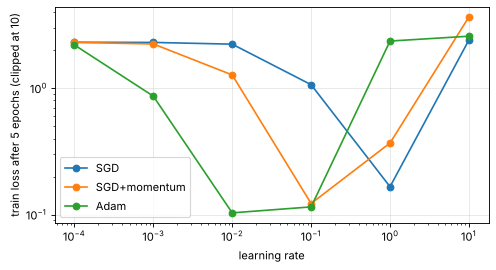

SGD           ['2.310', '2.303', '2.231', '1.067', '0.166', '2.408']
SGD+momentum  ['2.304', '2.239', '1.274', '0.123', '0.369', '3.668']
Adam          ['2.199', '0.866', '0.103', '0.115', '2.361', '2.579']


In [3]:
def make_mlp(): return nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 10))

def fit(model, make_opt, epochs=5, batch=64, seed=0, X=X_tr, y=y_tr):
    torch.manual_seed(seed); opt = make_opt(model.parameters()); history = []
    for _ in range(epochs):
        model.train(); perm = torch.randperm(len(X)); total = 0.0
        for i in range(0, len(X), batch):
            idx = perm[i:i + batch]
            loss = loss_fn(model(X[idx]), y[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(idx)
        history.append(total / len(X))
    return history

def accuracy(model, X, y):
    model.eval()
    with torch.no_grad(): return (model(X).argmax(1) == y).float().mean().item()

lrs = [1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0]
optimizers = {"SGD": lambda lr: (lambda p: torch.optim.SGD(p, lr=lr)),
              "SGD+momentum": lambda lr: (lambda p: torch.optim.SGD(p, lr=lr, momentum=0.9)),
              "Adam": lambda lr: (lambda p: torch.optim.Adam(p, lr=lr))}
final = {}
for name, mk in optimizers.items():
    final[name] = []
    for lr in lrs:
        torch.manual_seed(0); h = fit(make_mlp(), mk(lr))
        final[name].append(h[-1] if np.isfinite(h[-1]) else np.inf)
    plt.plot(lrs, np.clip(final[name], None, 10), "o-", label=name)
plt.xscale("log"); plt.yscale("log"); plt.xlabel("learning rate"); plt.ylabel("train loss after 5 epochs (clipped at 10)"); plt.legend(); plt.show()
for name in final: print(f"{name:13s}", ["%.3f" % v if np.isfinite(v) else "발산" for v in final[name]])

- 어떤 옵티마이저든 학습률이 너무 작으면 거의 안 배우고(손실이 ln 10 ≈ 2.30 근처에 머묾), 너무 크면 손실이 내려가지 않습니다. **가장 중요한 하이퍼파라미터는 학습률**입니다.
- 좋은 학습률의 **자릿수가 옵티마이저마다 다릅니다.** 이 문제에서는 SGD는 1 근처, 모멘텀 SGD는 0.1 근처, Adam은 0.01~0.1에서 가장 잘 됩니다. 논문의 실험 설정 표에서 옵티마이저와 학습률을 **함께** 확인해야 하는 이유입니다.
- 위 출력에서 "5 epoch 안에 손실 0.2 이하"를 달성한 학습률이 옵티마이저별로 몇 개인지 세어 보세요. Adam이 가장 많습니다(적당히 잡아도 되는 범위가 넓다).

## 3. 깊이와 잔차 연결 (He et al., 2015)

ResNet 논문의 출발점은 Figure 1입니다. *층을 더 쌓았더니 test 오차뿐 아니라 **train 오차**까지 나빠졌다.* 과적합이라면 train 오차는 좋아져야 하므로, 이것은 **최적화가 어려워지는 문제**(degradation)입니다.

같은 폭(64)의 블록 `Linear → BatchNorm → ReLU` 를 4개 / 40개 쌓은 plain 망과, 40개 블록 각각에 지름길(`x + F(x)`)을 단 잔차 망을 비교합니다.

✍️ **예측**: 15 epoch 뒤 **train 손실**이 가장 높은 것은 셋 중 무엇일까요?

plain, 4 blocks      초기 첫 층 기울기 크기 =      1.88   마지막 train 손실 = 0.027   train 정확도 = 0.998   test 정확도 = 0.974


plain, 40 blocks     초기 첫 층 기울기 크기 =   1085.16   마지막 train 손실 = 1.481   train 정확도 = 0.377   test 정확도 = 0.376


residual, 40 blocks  초기 첫 층 기울기 크기 =      3.23   마지막 train 손실 = 0.032   train 정확도 = 0.998   test 정확도 = 0.981


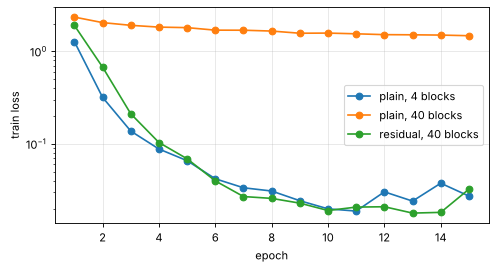

In [4]:
def unit(width): return nn.Sequential(nn.Linear(width, width), nn.BatchNorm1d(width), nn.ReLU())

class Residual(nn.Module):
    def __init__(self, width):
        super().__init__(); self.f = unit(width)
    def forward(self, x):
        return x + self.f(x)                      # y = x + F(x): F는 "입력에서 얼마나 바꿀지"만 배우면 된다

def make_net(depth, residual, width=64):
    blocks = [Residual(width) if residual else unit(width) for _ in range(depth)]
    return nn.Sequential(nn.Linear(64, width), *blocks, nn.BatchNorm1d(width), nn.Linear(width, 10))

def first_layer_grad_norm(model):
    model.train(); model.zero_grad(); loss_fn(model(X_tr[:256]), y_tr[:256]).backward()
    return model[0].weight.grad.norm().item()

configs = {"plain, 4 blocks": (4, False), "plain, 40 blocks": (40, False), "residual, 40 blocks": (40, True)}
for name, (depth, residual) in configs.items():
    torch.manual_seed(0); net = make_net(depth, residual)
    g0 = first_layer_grad_norm(net)
    hist = fit(net, lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9), epochs=15)
    plt.plot(range(1, 16), hist, "o-", label=name)
    print(f"{name:20s} 초기 첫 층 기울기 크기 = {g0:9.2f}   마지막 train 손실 = {hist[-1]:.3f}   train 정확도 = {accuracy(net, X_tr, y_tr):.3f}   test 정확도 = {accuracy(net, X_te, y_te):.3f}")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("train loss"); plt.legend(); plt.show()

- **plain 40블록은 plain 4블록보다 train 손실이 훨씬 높습니다.** 표현력은 더 큰데(4블록이 하는 일을 흉내 낼 수 있음) 학습이 안 되는 것이므로 과적합이 아니라 최적화 문제입니다. 논문 Figure 1의 관찰과 같은 방향입니다.
- **지름길 하나를 더했을 뿐인 잔차 40블록은 4블록만큼 잘 학습됩니다.** 블록이 항등 함수에 가까운 것만 배워도 되고, 기울기가 지름길을 따라 앞쪽 층까지 그대로 전달됩니다.
- 이 작은 MLP 실험에서는 plain 40블록의 초기 기울기 크기가 비정상적으로 큽니다(위 출력). 논문은 자신들의 CNN에서는 BatchNorm 덕분에 기울기 크기가 정상이었다고 보고하며 원인을 단정하지 않습니다. **현상(깊은 plain 망의 학습 오차 악화)과 해결책(지름길)** 이 재현된다는 점에 주목하세요.

## 4. 암기와 드롭아웃 (Srivastava et al., 2014)

학습 데이터를 300장으로 줄이고, 그중 **25%의 라벨을 일부러 틀리게** 바꿉니다. 큰 MLP(은닉 512×2)는 이것을 어떻게 처리할까요?

✍️ **예측**: (a) 틀린 라벨이 섞인 train 세트에서의 정확도는? (b) 드롭아웃을 켜면 test 정확도는 어떻게 될까요?

dropout=0.0:  오염된 train 정확도 = 1.000   test 정확도 = 0.713   test 손실 = 1.87


dropout=0.5:  오염된 train 정확도 = 1.000   test 정확도 = 0.767   test 손실 = 0.98


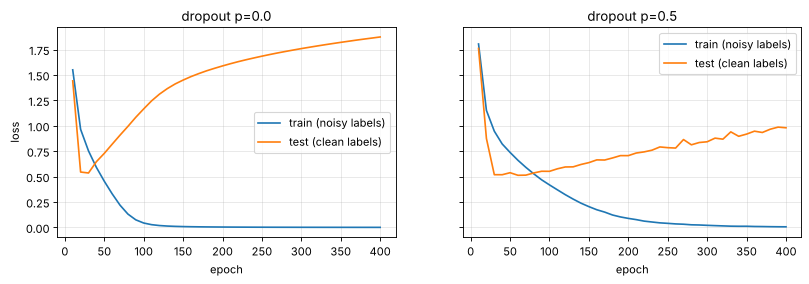

In [5]:
g = torch.Generator().manual_seed(0)
idx = torch.randperm(len(X_tr), generator=g)[:300]
X_small, y_noisy = X_tr[idx], y_tr[idx].clone()
flip = torch.rand(len(y_noisy), generator=g) < 0.25
y_noisy[flip] = torch.randint(0, 10, (int(flip.sum()),), generator=g)       # 라벨 오염

def big_mlp(p_drop):
    return nn.Sequential(nn.Linear(64, 512), nn.ReLU(), nn.Dropout(p_drop), nn.Linear(512, 512), nn.ReLU(), nn.Dropout(p_drop), nn.Linear(512, 10))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, p_drop in zip(axes, [0.0, 0.5]):
    torch.manual_seed(0); model = big_mlp(p_drop); opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    tr_curve, te_curve = [], []
    for epoch in range(400):
        model.train(); loss = loss_fn(model(X_small), y_noisy); opt.zero_grad(); loss.backward(); opt.step()
        if epoch % 10 == 9:
            model.eval()
            with torch.no_grad(): tr_curve.append(loss_fn(model(X_small), y_noisy).item()); te_curve.append(loss_fn(model(X_te), y_te).item())
    ax.plot(range(10, 401, 10), tr_curve, label="train (noisy labels)"); ax.plot(range(10, 401, 10), te_curve, label="test (clean labels)")
    ax.set_title(f"dropout p={p_drop}"); ax.set_xlabel("epoch"); ax.legend()
    print(f"dropout={p_drop}:  오염된 train 정확도 = {accuracy(model, X_small, y_noisy):.3f}   test 정확도 = {accuracy(model, X_te, y_te):.3f}   test 손실 = {te_curve[-1]:.2f}")
axes[0].set_ylabel("loss"); plt.show()

- 두 모델 모두 **틀린 라벨까지 전부 외웁니다**(오염된 train 정확도 ≈ 100%). 신경망은 무작위 라벨도 외울 만큼 용량이 큽니다 (Zhang et al., 2016).
- 드롭아웃이 없으면 test 손실이 학습이 진행될수록 **다시 올라갑니다**(과적합의 전형적인 그림). 드롭아웃을 켜면 test 정확도가 몇 %p 높고 test 손실은 훨씬 낮습니다.
- 드롭아웃은 매 스텝 무작위로 뉴런을 꺼서, 특정 뉴런 조합에 의존해 개별 표본을 외우는 것(co-adaptation)을 어렵게 만듭니다. 논문은 이를 "수많은 얇은 망의 앙상블을 근사"하는 것으로 설명합니다.

## 5. `model.train()` vs `model.eval()`

드롭아웃과 BatchNorm은 **학습할 때와 추론할 때 다르게 동작**합니다. 평가 전에 `model.eval()` 을 빼먹는 것은 가장 흔한 버그 중 하나입니다.

In [6]:
torch.manual_seed(0)
m = nn.Sequential(nn.Linear(64, 32), nn.BatchNorm1d(32), nn.ReLU(), nn.Dropout(0.5), nn.Linear(32, 10))
x = X_te[:4]
m.train(); a, b = m(x), m(x)
m.eval();  c, d = m(x), m(x)
print("train 모드: 같은 입력을 두 번 넣은 출력이 같은가?", torch.allclose(a, b))
print("eval  모드: 같은 입력을 두 번 넣은 출력이 같은가?", torch.allclose(c, d))

train 모드: 같은 입력을 두 번 넣은 출력이 같은가? False
eval  모드: 같은 입력을 두 번 넣은 출력이 같은가? True


- train 모드: 드롭아웃이 매번 다른 뉴런을 끄고, BatchNorm은 **그 배치의** 평균·분산을 씁니다 → 출력이 매번 다르고 배치 구성에 의존.
- eval 모드: 드롭아웃은 꺼지고, BatchNorm은 학습 중 모아 둔 **이동평균 통계**를 씁니다 → 결정적.

---
## 직접 해보기

1. **(학습률 스케줄)** 처음 `warmup` 스텝 동안 0에서 `max_lr`까지 선형으로 올리고 이후 코사인으로 0까지 내리는 함수 `lr_at(step)` 을 만들고 그래프로 그리세요. (대부분의 Transformer 학습이 쓰는 스케줄입니다.)
2. **(정규화 축)** shape (4, 3)인 텐서에 대해 BatchNorm과 LayerNorm을 **직접 계산**하고 `nn.BatchNorm1d`, `nn.LayerNorm` 의 출력과 비교하세요. 두 방법은 어느 축으로 평균을 내나요?
3. **(지름길 제거)** 3절의 `Residual.forward` 를 `return self.f(x)` 로 바꾸면 무엇과 같아지나요? 블록 수를 10, 20, 40으로 바꿔 plain 망의 train 손실이 어느 깊이부터 나빠지는지 찾아보세요.

In [7]:
# TODO 1: warmup + cosine 스케줄

# TODO 2: BatchNorm 과 LayerNorm 직접 계산

# TODO 3: plain 망의 깊이별 train 손실

---
## 정답 예시 (먼저 풀어 본 뒤 확인)

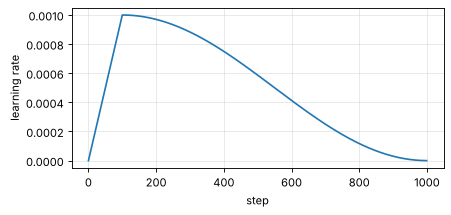

In [8]:
# 1. warmup + cosine
def lr_at(step, max_lr=1e-3, warmup=100, total=1000):
    if step < warmup: return max_lr * step / warmup
    progress = (step - warmup) / (total - warmup)
    return max_lr * 0.5 * (1 + np.cos(np.pi * progress))
plt.figure(figsize=(6, 2.6)); plt.plot([lr_at(s) for s in range(1000)]); plt.xlabel("step"); plt.ylabel("learning rate"); plt.show()

In [9]:
# 2. 정규화 축: BatchNorm은 "특성별로 배치 방향(행 방향)" 평균, LayerNorm은 "표본별로 특성 방향(열 방향)" 평균
t = torch.tensor([[1., 2., 3.], [2., 4., 6.], [0., 1., 5.], [3., 3., 3.5]])
bn_manual = (t - t.mean(0)) / torch.sqrt(t.var(0, unbiased=False) + 1e-5)
ln_manual = (t - t.mean(1, keepdim=True)) / torch.sqrt(t.var(1, unbiased=False, keepdim=True) + 1e-5)
bn = nn.BatchNorm1d(3); bn.train()
print("BatchNorm 일치:", torch.allclose(bn(t), bn_manual, atol=1e-5), "| LayerNorm 일치:", torch.allclose(nn.LayerNorm(3)(t), ln_manual, atol=1e-5))

BatchNorm 일치: True | LayerNorm 일치: True


In [10]:
# 3. 지름길을 빼면 plain 망과 같다. 깊이별 train 손실
for depth in [10, 20, 40]:
    torch.manual_seed(0); net = make_net(depth, residual=False)
    hist = fit(net, lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9), epochs=15)
    print(f"plain {depth:2d} blocks: 15 epoch 뒤 train 손실 = {hist[-1]:.3f}")

plain 10 blocks: 15 epoch 뒤 train 손실 = 0.088


plain 20 blocks: 15 epoch 뒤 train 손실 = 0.293


plain 40 blocks: 15 epoch 뒤 train 손실 = 1.481


**2번 해석**: BatchNorm은 배치 안의 **다른 표본들**을 이용하므로 배치 크기·구성에 의존하고 train/eval 동작이 다릅니다. LayerNorm은 **표본 하나 안에서** 계산하므로 배치와 무관합니다. 문장 길이가 제각각이고 배치 통계가 불안정한 시퀀스 모델(Transformer)이 LayerNorm을 쓰는 이유입니다.

---
## 논문으로 돌아가기

| 방금 한 것 | 논문에서 확인할 곳 |
|---|---|
| 1절 | Adam 논문의 Algorithm 1 상자와 bias correction을 설명하는 절. 실험 그림에서 비교한 옵티마이저 목록 |
| 3절 | ResNet 논문 Figure 1(문제 제기), Figure 2(잔차 블록), ImageNet 실험의 plain-18/34 vs ResNet-18/34 표와 학습 곡선 |
| 4절 | Dropout 논문의 Figure 1(얇아진 망)과 "test 때는 가중치에 p를 곱한다"는 설명 — PyTorch는 반대로 train 때 1/(1-p)를 곱한다(inverted dropout) |
| 5절 | BatchNorm 논문의 학습/추론 알고리즘 두 개가 왜 다른지 |

## 기억 점검

1. Adam의 $m$ 과 $v$ 는 각각 무엇의 이동평균인가? bias correction은 왜 필요한가?
2. Adam의 한 스텝 크기가 기울기의 크기에 거의 의존하지 않는 이유는?
3. ResNet이 말하는 degradation 문제는 과적합과 어떻게 다른가? 무엇을 보고 구별하나?
4. 잔차 블록 $y=x+F(x)$ 에서 $F$ 가 배우는 것은 무엇인가?
5. 드롭아웃을 쓴 모델을 평가할 때 `model.eval()` 을 빼먹으면 어떤 일이 생기나?

<details><summary>답 확인</summary>

1. $m$: 기울기(1차 모멘트), $v$: 기울기 제곱(2차 모멘트). 둘 다 0에서 시작해 초반에 0 쪽으로 치우치므로 $1-\beta^t$ 로 나눠 보정한다.
2. 갱신량이 $\hat m/\sqrt{\hat v}$ 꼴이라 기울기의 스케일이 분자·분모에서 상쇄된다. 스텝은 대략 학습률 크기로 제한된다.
3. degradation은 층을 늘렸을 때 **train 오차부터** 나빠지는 현상(최적화 문제). 과적합은 train 오차는 좋아지는데 test 오차가 나빠지는 것. train 곡선을 보면 구별된다.
4. 입력과 원하는 출력의 차이(잔차). 아무것도 바꿀 필요가 없으면 $F=0$ 만 배우면 되어 항등 함수가 쉽다.
5. 추론 때도 뉴런이 무작위로 꺼져 출력이 매번 달라지고 성능이 낮게 측정된다(BatchNorm이 있으면 배치 통계에 의존하게 된다).
</details>